In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from scipy.cluster.hierarchy import linkage, dendrogram

print("Libraries Imported Successfully!")

Libraries Imported Successfully!


In [3]:
df = pd.read_csv("sales_data_sample.csv", encoding="latin1")

print("First 5 Records:")
display(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

First 5 Records:


,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID,...,ADDRESSLINE1,ADDRESSLINE2,CITY,STATE,POSTALCODE,COUNTRY,TERRITORY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
0,10107,30,95.70,2,2871.00,2/24/2003 0:00,Shipped,1,2,2003,...,897 Long Airport Avenue,NaN,NYC,NY,10022,USA,NaN,Yu,Kwai,Small
1,10121,34,81.35,5,2765.90,5/7/2003 0:00,Shipped,2,5,2003,...,59 rue de l'Abbaye,NaN,Reims,NaN,51100,France,EMEA,Henriot,Paul,Small
2,10134,41,94.74,2,3884.34,7/1/2003 0:00,Shipped,3,7,2003,...,27 rue du Colonel Pierre Avia,NaN,Paris,NaN,75508,France,EMEA,Da Cunha,Daniel,Medium
3,10145,45,83.26,6,3746.70,8/25/2003 0:00,Shipped,3,8,2003,...,78934 Hillside Dr.,NaN,Pasadena,CA,90003,USA,NaN,Young,Julie,Medium
4,10159,49,100.00,14,5205.27,10/10/2003 0:00,Shipped,4,10,2003,...,7734 Strong St.,NaN,San Francisco,CA,NaN,USA,NaN,Brown,Julie,Medium



Dataset Shape:
(2823, 25)

Column Names:
['ORDERNUMBER', 'QUANTITYORDERED', 'PRICEEACH', 'ORDERLINENUMBER', 'SALES', 'ORDERDATE', 'STATUS', 'QTR_ID', 'MONTH_ID', 'YEAR_ID', 'PRODUCTLINE', 'MSRP', 'PRODUCTCODE', 'CUSTOMERNAME', 'PHONE', 'ADDRESSLINE1', 'ADDRESSLINE2', 'CITY', 'STATE', 'POSTALCODE', 'COUNTRY', 'TERRITORY', 'CONTACTLASTNAME', 'CONTACTFIRSTNAME', 'DEALSIZE']

Missing Values:
ORDERNUMBER            0
QUANTITYORDERED        0
PRICEEACH              0
ORDERLINENUMBER        0
SALES                  0
ORDERDATE              0
STATUS                 0
QTR_ID                 0
MONTH_ID               0
YEAR_ID                0
PRODUCTLINE            0
MSRP                   0
PRODUCTCODE            0
CUSTOMERNAME           0
PHONE                  0
ADDRESSLINE1           0
ADDRESSLINE2        2521
CITY                   0
STATE               1486
POSTALCODE            76
COUNTRY                0
TERRITORY           1074
CONTACTLASTNAME        0
CONTACTFIRSTNAME       0
DEALSIZE

In [4]:
print("Duplicate Records:", df.duplicated().sum())

df = df.drop_duplicates()

print("\nAfter Removing Duplicates:")
print("Dataset Shape:", df.shape)
print("Duplicate Records:", df.duplicated().sum())

Duplicate Records: 0

After Removing Duplicates:
Dataset Shape: (2823, 25)
Duplicate Records: 0


In [5]:
features = ["QUANTITYORDERED", "PRICEEACH", "SALES"]

X = df[features].copy()

X = X.dropna()

print("Selected Features:")
display(X.head())

print("\nDataset Shape:")
print(X.shape)

Selected Features:


,QUANTITYORDERED,PRICEEACH,SALES
0,30,95.70,2871.00
1,34,81.35,2765.90
2,41,94.74,3884.34
3,45,83.26,3746.70
4,49,100.00,5205.27



Dataset Shape:
(2823, 3)


In [6]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Data Normalization Completed!")

Data Normalization Completed!


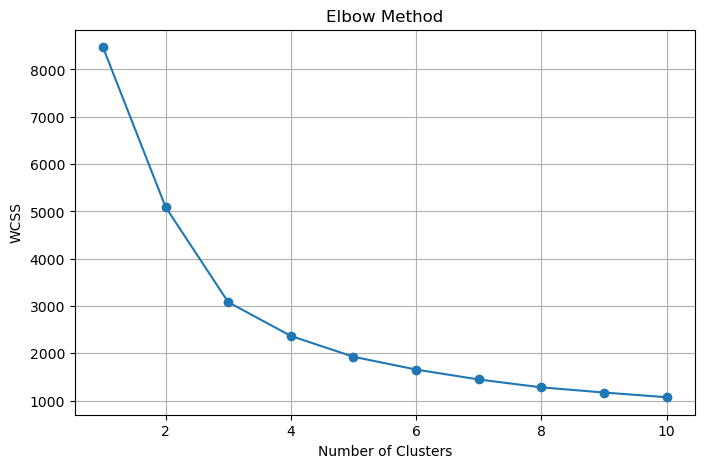

In [7]:
wcss = []

for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker="o")

plt.title("Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.grid(True)

plt.show()

In [8]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

clusters = kmeans.fit_predict(X_scaled)

X["Cluster"] = clusters

print("K-Means Clustering Completed!")

display(X.head(10))

print("\nCluster Counts:")
print(X["Cluster"].value_counts())

K-Means Clustering Completed!


,QUANTITYORDERED,PRICEEACH,SALES,Cluster
0,30,95.70,2871.00,2
1,34,81.35,2765.90,2
2,41,94.74,3884.34,1
3,45,83.26,3746.70,1
4,49,100.00,5205.27,1
5,36,96.66,3479.76,2
6,29,86.13,2497.77,2
7,48,100.00,5512.32,1
8,22,98.57,2168.54,2
9,41,100.00,4708.44,1



Cluster Counts:
Cluster
2    1035
1     907
0     881
Name: count, dtype: int64


In [9]:
centers = scaler.inverse_transform(kmeans.cluster_centers_)

centers_df = pd.DataFrame(centers, columns=features)

print("K-Means Cluster Centers:")
display(centers_df)

print("\nCluster Summary:")
cluster_summary = X.groupby("Cluster")[features].mean()

display(cluster_summary)

print("\nCluster Counts:")
print(X["Cluster"].value_counts().sort_index())

K-Means Cluster Centers:


,QUANTITYORDERED,PRICEEACH,SALES
0,35.125993,57.130216,2009.829955
1,43.843612,96.623910,5581.559273
2,27.380077,94.876054,3088.890561



Cluster Summary:


,QUANTITYORDERED,PRICEEACH,SALES
Cluster,,,
0,35.125993,57.130216,2009.829955
1,43.847850,96.637795,5584.007299
2,27.392271,94.865575,3089.153662



Cluster Counts:
Cluster
0     881
1     907
2    1035
Name: count, dtype: int64


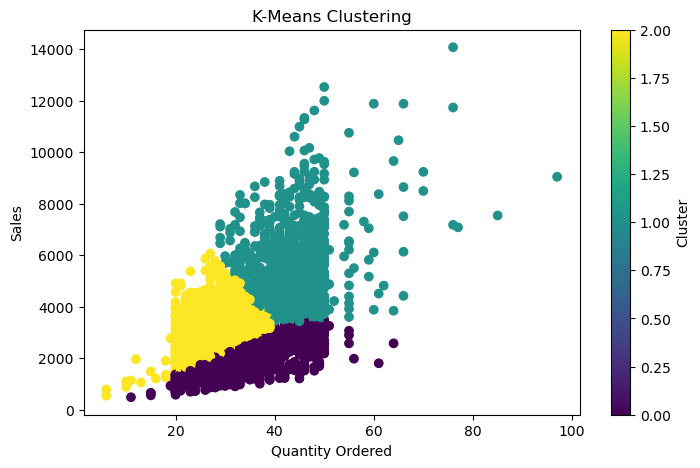

In [10]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X["QUANTITYORDERED"],
    X["SALES"],
    c=X["Cluster"],
    cmap="viridis"
)

plt.title("K-Means Clustering")
plt.xlabel("Quantity Ordered")
plt.ylabel("Sales")
plt.colorbar(label="Cluster")

plt.show()

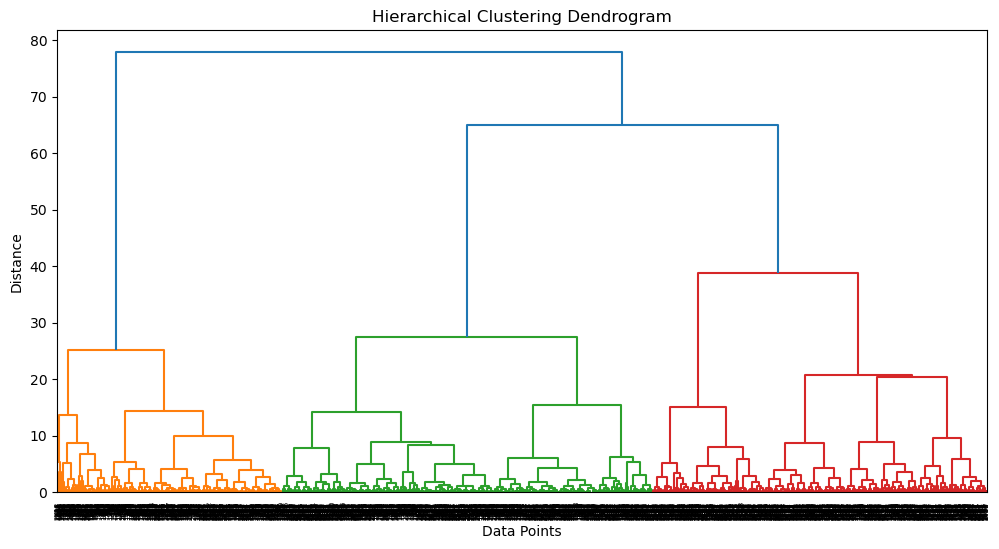

In [11]:
linked = linkage(X_scaled, method="ward")

plt.figure(figsize=(12, 6))

dendrogram(linked)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Data Points")
plt.ylabel("Distance")

plt.show()

In [12]:
hc = AgglomerativeClustering(n_clusters=3)

hc_clusters = hc.fit_predict(X_scaled)

X["Hierarchical_Cluster"] = hc_clusters

print("Hierarchical Clustering Completed!")

display(X.head(10))

print("\nHierarchical Cluster Counts:")
print(X["Hierarchical_Cluster"].value_counts())

Hierarchical Clustering Completed!


,QUANTITYORDERED,PRICEEACH,SALES,Cluster,Hierarchical_Cluster
0,30,95.70,2871.00,2,2
1,34,81.35,2765.90,2,2
2,41,94.74,3884.34,1,1
3,45,83.26,3746.70,1,0
4,49,100.00,5205.27,1,1
5,36,96.66,3479.76,2,2
6,29,86.13,2497.77,2,2
7,48,100.00,5512.32,1,1
8,22,98.57,2168.54,2,2
9,41,100.00,4708.44,1,1



Hierarchical Cluster Counts:
Hierarchical_Cluster
2    1124
0    1014
1     685
Name: count, dtype: int64


In [13]:
print("Conclusion:")
print("K-Means and Hierarchical Clustering are implemented successfully.")
print("The Elbow Method is used to determine the number of clusters.")
print("K-Means clustering divides the data into 3 clusters.")
print("Hierarchical Clustering also divides the data into 3 clusters.")
print("Data normalization is performed using StandardScaler.")

Conclusion:
K-Means and Hierarchical Clustering are implemented successfully.
The Elbow Method is used to determine the number of clusters.
K-Means clustering divides the data into 3 clusters.
Hierarchical Clustering also divides the data into 3 clusters.
Data normalization is performed using StandardScaler.
